# 03. 놓친 불량은 왜 놓쳤나 — 위험 순위·위치·학습 사례
02에서 10~20% 검사로 불량의 60~80%는 찾지만, 나머지를 찾으려면 검사량이 급격히 늘었다.
여기서는 각 불량이 위험 순위 어디에 있었는지, 그리고 그 불량의 **위치에 학습 구간(같은 fold 밖) 불량 사례가 있었는지**를 본다.
대상: 도메인 CatBoost(1차 탐색 기준 모델)와 도메인 TabICLv2(01번 최고), 5개 시드 모두.

이것은 모델이 낮은 순위를 준 이유에 대한 진단이며, 실제 불량 발생 원인을 밝힌 것은 아니다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import br
from br import features as F, budget as B, plot as P
from wl.metrics import within_loc_auroc, inclusion_prob
P.setup(); pd.set_option("display.width", 220)
df = F.load(); y = df.y.values; loc = df["loc"].values
oof = pd.read_pickle(br.RES / "polito_oof.pkl").sort_values(["label", "seed", "row"])
MODELS = ["CatBoost·도메인90", "TabICLv2·도메인90"]

def defect_table(g):
    """불량 행마다: fold 안 위험 순위 백분위, 학습 구간에 같은 위치 불량이 있었는지."""
    s, fold = g.score.values, g.fold.values
    pct = pd.Series(s).groupby(fold).rank(ascending=False, method="average").values / pd.Series(fold).map(pd.Series(fold).value_counts()).values
    rows = []
    for i in np.flatnonzero(y == 1):
        tr = fold != fold[i]
        rows.append(dict(row=i, loc=loc[i], fold=fold[i], pct=pct[i] * 100,
                         loc_train_def=int(((loc == loc[i]) & tr & (y == 1)).sum()),
                         loc_train_n=int(((loc == loc[i]) & tr).sum())))
    return pd.DataFrame(rows)

D = pd.concat([defect_table(g).assign(label=lab, seed=s) for (lab, s), g in oof[oof.label.isin(MODELS)].groupby(["label", "seed"])])
D["학습에 같은 위치 불량"] = np.where(D.loc_train_def > 0, "있음", "없음")
BANDS = [0, 10, 20, 50, 80, 100]
D["순위 구간"] = pd.cut(D.pct, BANDS, labels=["상위 10%", "10~20%", "20~50%", "50~80%", "80% 밖"], include_lowest=True)

## 1. 불량 79개가 위험 순위 어디에 있었나 (시드 평균 개수)

In [2]:
t = D.groupby(["label", "순위 구간"], observed=False).size().unstack() / 5
t["합계"] = t.sum(axis=1)
t.round(1)

순위 구간,상위 10%,10~20%,20~50%,50~80%,80% 밖,합계
label,,,,,,
CatBoost·도메인90,48.0,12.2,10.6,6.0,2.2,79.0
TabICLv2·도메인90,53.2,12.8,7.2,5.4,0.4,79.0


## 2. 학습 구간에 같은 위치의 불량 사례가 있었는가 → 순위 구간별
'없음' = 이 불량이 생긴 위치에서, 다른 fold(학습 구간)에 불량이 한 번도 없었다.

In [3]:
t2 = D.groupby(["label", "학습에 같은 위치 불량", "순위 구간"], observed=False).size().unstack() / 5
t2["합계"] = t2.sum(axis=1)
display(t2.round(1))
for lab in MODELS:
    d = D[D.label == lab]
    caught = d[d.pct <= 20]; missed = d[d.pct > 20]
    print(f"[{lab}] 20% 검사 시 포착 불량 중 '없음' 비율 {(caught['학습에 같은 위치 불량']=='없음').mean():.0%}, "
          f"미포착 불량 중 '없음' 비율 {(missed['학습에 같은 위치 불량']=='없음').mean():.0%}")

순위 구간                        상위 10%  10~20%  20~50%  50~80%  80% 밖    합계
label          학습에 같은 위치 불량                                             
CatBoost·도메인90 없음               5.6     4.4     4.2     4.0    1.6  19.8
               있음              42.4     7.8     6.4     2.0    0.6  59.2
TabICLv2·도메인90 없음               6.8     5.2     2.8     4.6    0.4  19.8
               있음              46.4     7.6     4.4     0.8    0.0  59.2

[CatBoost·도메인90] 20% 검사 시 포착 불량 중 '없음' 비율 17%, 미포착 불량 중 '없음' 비율 52%
[TabICLv2·도메인90] 20% 검사 시 포착 불량 중 '없음' 비율 18%, 미포착 불량 중 '없음' 비율 60%


## 3. 위치 73·84(불량 25개 집중)의 영향
같은 비율을 두 위치를 빼고 다시 계산한다. 빼면 남는 불량은 54개.

In [4]:
hot = np.isin(loc, [73, 84])
rows = []
for lab in MODELS + ["위치별 과거 불량률"]:
    for s in range(5):
        g = oof[(oof.label == lab) & (oof.seed == s)]
        sc, fo = g.score.values, g.fold.values
        r = {"모델": lab, "seed": s}
        for b in (0.1, 0.2):
            r[f"전체 {int(b*100)}%"] = B.hits_at(y, sc, fo, b)[1] / y.sum()
            r[f"73·84 제외 {int(b*100)}%"] = B.hits_at(y[~hot], sc[~hot], fo[~hot], b)[1] / y[~hot].sum()
        r["같은 fold·위치 안 AUROC"] = within_loc_auroc(y, sc, np.char.add(fo.astype(str), "_" + loc.astype(str)))
        rows.append(r)
h = pd.DataFrame(rows).groupby("모델").mean().drop(columns="seed")
print("포착률(시드 평균). 같은 위치 안 AUROC 0.5 = 무작위")
h.round(3)

포착률(시드 평균). 같은 위치 안 AUROC 0.5 = 무작위


,전체 10%,73·84 제외 10%,전체 20%,73·84 제외 20%,같은 fold·위치 안 AUROC
모델,,,,,
CatBoost·도메인90,0.613,0.485,0.765,0.678,0.646
TabICLv2·도메인90,0.681,0.578,0.841,0.781,0.732
위치별 과거 불량률,0.521,0.355,0.733,0.630,0.500


## 4. 위치마다 같은 비율을 검사하는 정책
위치 간 위험 차이를 쓰지 않고, 각 위치 안에서 점수 상위만 고르면 어떻게 되는가. 위치 내 판별력만 남긴 확인용이다.

In [5]:
rows = []
for lab in MODELS:
    for s in range(5):
        g = oof[(oof.label == lab) & (oof.seed == s)]
        sc, fo = g.score.values, g.fold.values
        grp = np.char.add(fo.astype(str), "_" + loc.astype(str))
        for b in (0.1, 0.2, 0.3):
            ug, gi = np.unique(grp, return_inverse=True)
            k = b * np.bincount(gi)          # 그룹이 1~4개로 작아 올림하면 검사량이 부풀므로 기대 개수(소수)로 배정
            p = inclusion_prob(sc, k, gi)
            rows.append(dict(모델=lab, seed=s, 예산=f"{int(b*100)}%", 검사수=k.sum(), 포착률=(p * y).sum() / y.sum()))
pol = pd.DataFrame(rows).groupby(["모델", "예산"])[["검사수", "포착률"]].mean()
pol.round(3)

검사수    포착률
모델             예산               
CatBoost·도메인90 10%  197.6  0.135
               20%  395.2  0.270
               30%  592.8  0.397
TabICLv2·도메인90 10%  197.6  0.150
               20%  395.2  0.299
               30%  592.8  0.434

## 5. 그림 — 불량 하나하나의 위험 순위 (시드 0)
점 하나 = 실제 불량 1개. 가로 = fold 안 위험 순위 백분위(왼쪽일수록 먼저 검사). 색 = 학습 구간에 같은 위치 불량 사례 유무.

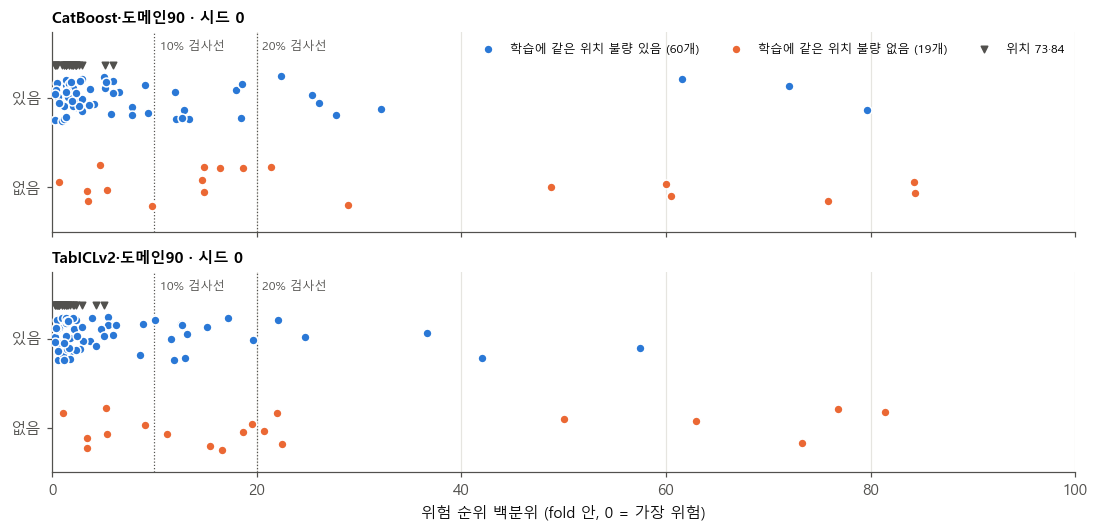

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
rng = np.random.default_rng(0)
for ax, lab in zip(axes, MODELS):
    d = D[(D.label == lab) & (D.seed == 0)]
    for cat, col, yy in [("있음", P.PAL[0], 1), ("없음", P.PAL[1], 0)]:
        e = d[d["학습에 같은 위치 불량"] == cat]
        ax.scatter(e.pct, yy + rng.uniform(-.25, .25, len(e)), s=34, color=col, edgecolor="white", linewidth=1,
                   label=f"학습에 같은 위치 불량 {cat} ({len(e)}개)", zorder=3)
    hh = d[np.isin(d["loc"], [73, 84])]
    ax.scatter(hh.pct, np.where(hh.loc_train_def > 0, 1, 0) + 0.38, marker="v", s=18, color=P.INK2, label="위치 73·84", zorder=3)
    for b in (10, 20):
        ax.axvline(b, color=P.INK2, lw=.8, ls=":")
        ax.text(b + .5, 1.55, f"{b}% 검사선", color=P.INK2, fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["없음", "있음"]); ax.set_ylim(-.5, 1.75)
    ax.set_title(lab + " · 시드 0", loc="left", fontweight="bold", fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[1].set_xlabel("위험 순위 백분위 (fold 안, 0 = 가장 위험)"); axes[1].set_xlim(0, 100)
P.save(fig, "04_missed_rank"); plt.show()

## 6. 그림 — 순위 구간별 불량 수, 학습 사례 유무로 나눔 (5시드 평균)

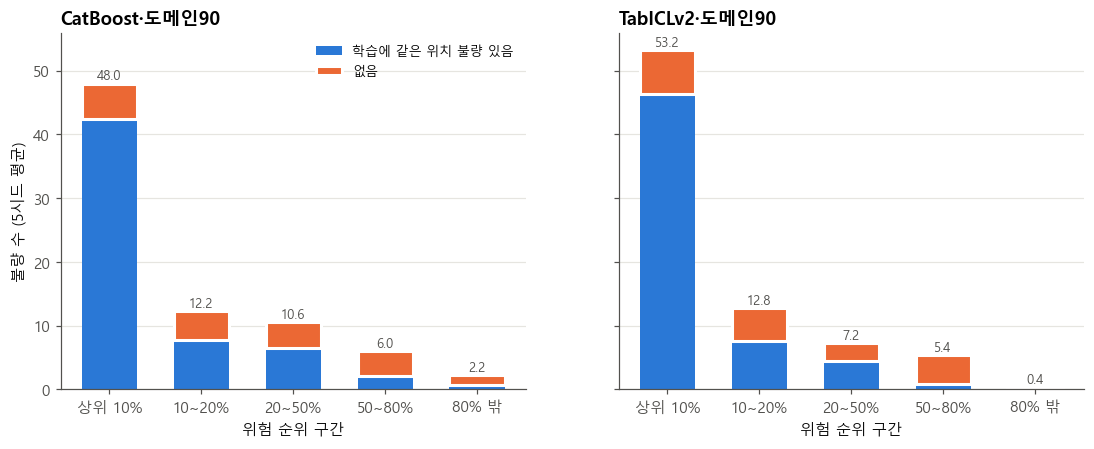

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
cats = ["상위 10%", "10~20%", "20~50%", "50~80%", "80% 밖"]
for ax, lab in zip(axes, MODELS):
    tt = t2.loc[lab][cats]
    x = np.arange(len(cats))
    a1 = tt.loc["있음"].values; a0 = tt.loc["없음"].values
    ax.bar(x, a1, .6, color=P.PAL[0], label="학습에 같은 위치 불량 있음")
    ax.bar(x, a0, .6, bottom=a1, color=P.PAL[1], label="없음", edgecolor="white", linewidth=2)
    for xx, v1, v0 in zip(x, a1, a0):
        ax.text(xx, v1 + v0 + .6, f"{v1+v0:.1f}", ha="center", fontsize=8.5, color=P.INK2)
    ax.set_xticks(x); ax.set_xticklabels(cats); ax.set_title(lab, loc="left", fontweight="bold")
    ax.set_xlabel("위험 순위 구간"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("불량 수 (5시드 평균)"); axes[0].legend(fontsize=8.5)
P.save(fig, "05_missed_bands"); plt.show()